# 03 - Exploratory Data Analysis (EDA)

## Objective

The main objectives are to:

- Understand the statistical properties of the data.
- Analyze individual attribute distributions.
- Investigate relationships between attributes.
- Identify correlations and potential redundancy.
- Explore differences between Information Operations
  (IO) and control accounts.
- Identify useful features for account-level profiling
  and subsequent clustering.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
DATA_PATH = Path("data_processed/df_clean_final.csv.gz")

print("Dataset exists:", DATA_PATH.exists())

Dataset exists: True


In [3]:
df_preview = pd.read_csv(DATA_PATH, nrows=5, dtype="string")

display(df_preview)

print("Number of attributes:", len(df_preview.columns))
print("\nAttributes:")

for column in df_preview.columns:
    print(column)

,ioCountry,postid,post_text,application_name,post_language,in_reply_to_postid,in_reply_to_accountid,post_time,accountid,account_profile_description,follower_count,following_count,account_creation_date,is_repost,reposted_accountid,reposted_postid,hashtags,urls,account_mentions,is_control
0,ecuador,0bafe020a260495bee38b98fde83668d924454019b,Vamos a cambiar la forma de hacer comunicación...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 02:52:00+00:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528.0,2619.0,2010-03-11,False,<NA>,<NA>,[],[],[],False
1,ecuador,608fba51f2460c7f1ca527dfc48de2bc858d4ad201,"Damos servicio de manejo de prensa, elaboració...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 03:08:00+00:00,22de67d991b31493165b9270f7d8b5b4ce712d5fc8,"#Periodismo, #RelacionesPúblicas, #Comunicac...",1528.0,2619.0,2010-03-11,False,<NA>,<NA>,[],[],[],False
2,ecuador,514b2c38b26e240cac85382be74ed7d61a02468ac1,@db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,f29b32f8dbaa1e0f00152decbcc2bd93dddc740464,db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302,2010-03-13 15:26:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28,False,<NA>,<NA>,[],[],['db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302'],False
3,ecuador,e82a816068e88387d19430348f0420b040e0d11b4e,"Mario, debemos denuciar que en los poderes pub...",2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 15:32:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28,False,<NA>,<NA>,[],[],[],False
4,ecuador,13ed6aaeec4fffaf840f1c42ff88f5ab2cb324be64,Tambien debemos estar claro que la oposición e...,2727201c363b6fc4afe259ba4094ae0c49cb4df224,<NA>,<NA>,<NA>,2010-03-13 15:35:00+00:00,2c6c0ef5f445760177b016e33b36809bde3c7ac241,<NA>,35.0,215.0,2010-01-28,False,<NA>,<NA>,[],[],[],False


Number of attributes: 20

Attributes:
ioCountry
postid
post_text
application_name
post_language
in_reply_to_postid
in_reply_to_accountid
post_time
accountid
account_profile_description
follower_count
following_count
account_creation_date
is_repost
reposted_accountid
reposted_postid
hashtags
urls
account_mentions
is_control


## B. Descriptive Statistics

This section investigates the statistical characteristics
of the cleaned dataset, including central tendency,
dispersion, and variability.

The objective is to better understand the data and
identify potentially informative features for
account-level profiling and clustering.

we will start with the follower and following counts, it will be done at the accounts level, first lets check how many accounts do we have

In [4]:
CHUNK_SIZE = 200_000

columns = [
    "ioCountry",
    "accountid",
    "post_time",
    "follower_count",
    "following_count"
]

account_keys = ["ioCountry", "accountid"]

df_accounts = pd.DataFrame()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype={"accountid": "string", "ioCountry": "string"},
    chunksize=CHUNK_SIZE
):
    chunk["post_time"] = pd.to_datetime(
        chunk["post_time"],
        errors="coerce",
        utc=True
    )

    chunk = chunk.dropna(
        subset=account_keys + ["post_time"]
    )

    # Keep the most recent record of each account
    chunk = (
        chunk.sort_values("post_time", kind="stable")
        .drop_duplicates(subset=account_keys, keep="last")
    )

    # Combine with previously processed accounts
    df_accounts = pd.concat(
        [df_accounts, chunk],
        ignore_index=True
    )

    df_accounts = (
        df_accounts.sort_values("post_time", kind="stable")
        .drop_duplicates(subset=account_keys, keep="last")
    )

df_accounts = df_accounts.reset_index(drop=True)

print(f"Number of accounts: {len(df_accounts):,}")

display(df_accounts.head())

Number of accounts: 86,525


,ioCountry,post_time,accountid,follower_count,following_count
0,russia_1,2009-11-22 23:59:26+00:00,c5bf20b8b883fd0c5689c64bee8ae7bd81d97698f6,125.0,0.0
1,russia_1,2009-11-23 23:59:58+00:00,be64bf6b9b53f31e552be1bcaa0299143a51797dce,3248.0,2473.0
2,russia_1,2009-11-23 23:59:58+00:00,703a8bb61d6ddb7168f50bebc3a753d88ba09a2d98,33.0,22.0
3,russia_1,2009-11-24 23:59:58+00:00,2e1e7459112a2f14ce968cbc6e967725426962cb85,469.0,537.0
4,russia_1,2009-11-24 23:59:58+00:00,ae36bdb6544c22720f180f2b079218b50b7d3a098e,68.0,167.0


In [5]:
numerical_attributes = [
    "follower_count",
    "following_count"
]

display(
    df_accounts[numerical_attributes]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
follower_count,86521.0,10163.087690,185853.570717,0.0,97.0,385.0,1433.0,13815.0,101518.80,19912528.0
following_count,86522.0,1811.917524,12883.529464,0.0,118.0,406.0,1235.0,5001.0,21654.17,2301841.0


Visualisation:
- Each histogram contains 50 bins, where each bin represents
  an interval of follower or following counts
- The height of each bin represents the number of accounts
within that interval.

We used only the 95th percentile because including extremely large values would stretch the X-axis and make the distribution of most accounts difficult to observe.


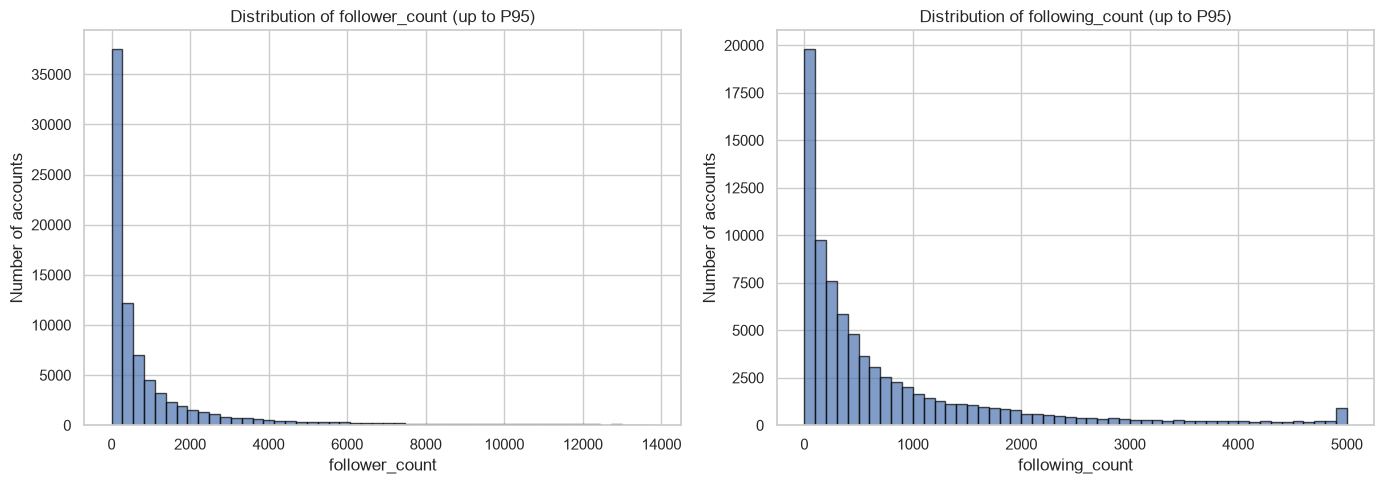

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, ["follower_count", "following_count"]):

    values = df_accounts[column].dropna()
    upper_limit = values.quantile(0.95)

    ax.hist(
        values[values <= upper_limit],
        bins=50,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column} (up to P95)")
    ax.set_xlabel(column)
    ax.set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

Now we will move to Account Age and Activity Lifespan.

These attributes could be particularly useful for understanding behavioral differences between IO and control accounts.
Because IO accounts may be created and operated for specific information campaigns, while control accounts may be used for ordinary, long-term social media activity.

In [7]:
columns = [
    "ioCountry",
    "accountid",
    "account_creation_date",
    "post_time"
]

df_temporal = pd.DataFrame()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype={"accountid": "string", "ioCountry": "string"},
    chunksize=CHUNK_SIZE
):
    chunk["post_time"] = pd.to_datetime(
        chunk["post_time"], errors="coerce", utc=True
    )

    chunk["account_creation_date"] = pd.to_datetime(
        chunk["account_creation_date"], errors="coerce", utc=True
    )

    chunk = chunk.groupby(account_keys).agg(
        creation_date=("account_creation_date", "min"),
        first_post=("post_time", "min"),
        last_post=("post_time", "max")
    ).reset_index()

    df_temporal = pd.concat(
        [df_temporal, chunk], ignore_index=True
    )

    df_temporal = df_temporal.groupby(account_keys).agg(
        creation_date=("creation_date", "min"),
        first_post=("first_post", "min"),
        last_post=("last_post", "max")
    ).reset_index()

In [8]:
df_temporal["account_age_days"] = (
    df_temporal["last_post"].dt.normalize()
    - df_temporal["creation_date"].dt.normalize()
).dt.days

df_temporal["activity_lifespan_days"] = (
    df_temporal["last_post"].dt.normalize()
    - df_temporal["first_post"].dt.normalize()
).dt.days

display(
    df_temporal[[
        "account_age_days",
        "activity_lifespan_days"
    ]].describe(
        percentiles=[0.25, 0.50, 0.75, 0.95, 0.99]
    ).T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
account_age_days,86525.0,993.341000,887.809747,0.0,243.0,750.0,1509.0,2815.0,3353.0,4493.0
activity_lifespan_days,86525.0,40.498943,163.007385,0.0,0.0,0.0,0.0,255.0,889.0,3288.0


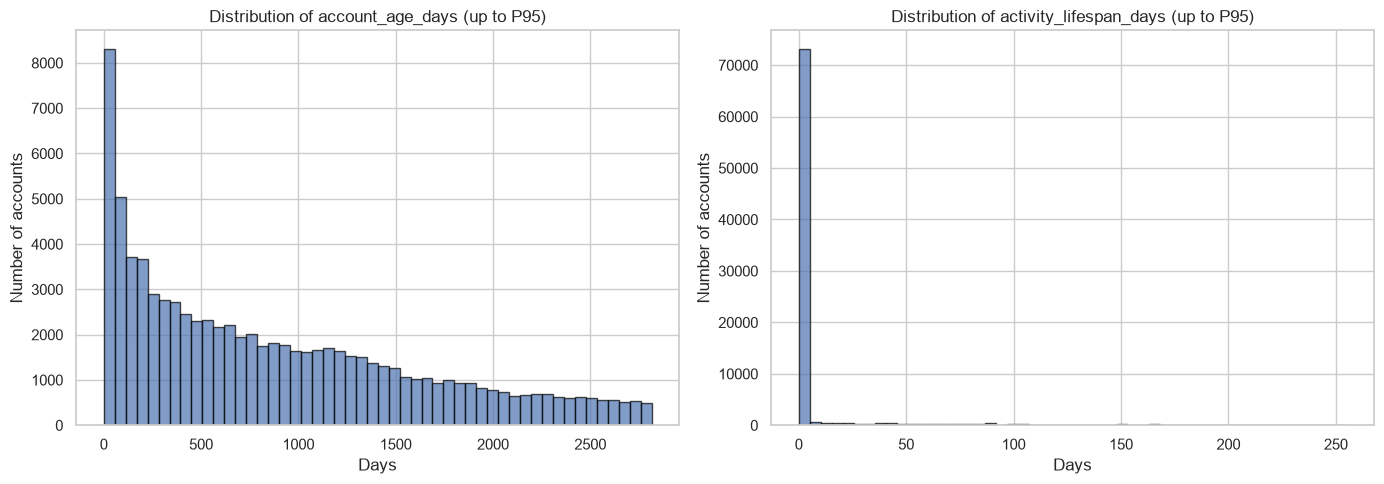

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(
    axes, ["account_age_days", "activity_lifespan_days"]
):
    values = df_temporal[column].dropna()
    upper_limit = values.quantile(0.95)

    ax.hist(
        values[values <= upper_limit],
        bins=50,
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column} (up to P95)")
    ax.set_xlabel("Days")
    ax.set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

### B.3 Number of Posts per Account

We calculate the total number of observed posts for each
account

In [10]:
from collections import Counter

post_counts = Counter()

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=account_keys,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    counts = chunk.groupby(account_keys).size()
    post_counts.update(counts.to_dict())

df_activity = pd.DataFrame(
    [(country, account, count)
     for (country, account), count in post_counts.items()],
    columns=["ioCountry", "accountid", "post_count"]
)

In [11]:
display(
    df_activity[["post_count"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
post_count,86525.0,100.696804,1123.533127,1.0,6.0,23.0,84.0,240.0,1386.0,265448.0


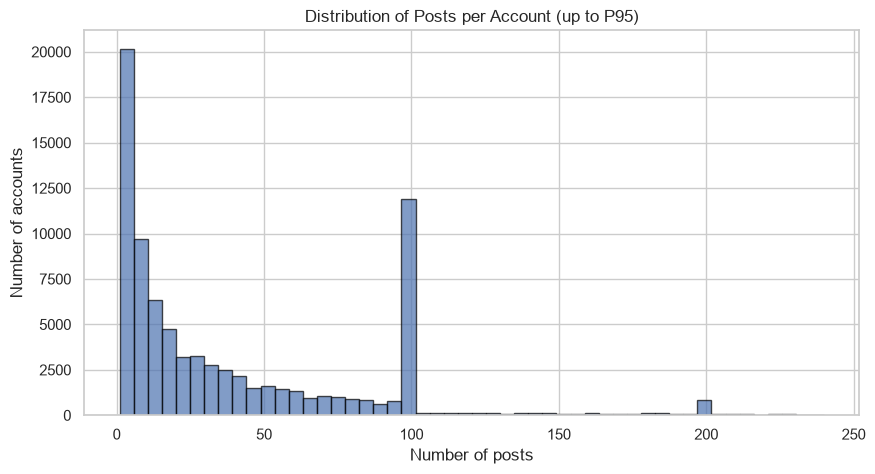

In [12]:
values = df_activity["post_count"]
upper_limit = values.quantile(0.95)

plt.figure(figsize=(10, 5))

plt.hist(
    values[values <= upper_limit],
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Posts per Account (up to P95)")
plt.xlabel("Number of posts")
plt.ylabel("Number of accounts")
plt.show()

There are 2 spikes at 100 and at 200 posts. This unusual concentration requires further
investigation.

In [13]:
display(
    df_activity["post_count"]
    .value_counts()
    .head(15)
    .rename("Number of accounts")
    .to_frame()
)

,Number of accounts
post_count,
99,11543
1,6027
2,4560
3,3738
4,3089
5,2761
6,2395
7,2123
8,1989


In [14]:
summary_99 = df_activity.groupby("ioCountry").agg(
    total_accounts=("post_count", "size"),
    accounts_with_99_posts=("post_count", lambda x: (x == 99).sum())
)

summary_99["percentage"] = (
    summary_99["accounts_with_99_posts"]
    / summary_99["total_accounts"] * 100
)

display(
    summary_99.sort_values("percentage", ascending=False).round(2)
)

,total_accounts,accounts_with_99_posts,percentage
ioCountry,,,
iran_1,5675,910,16.04
russia_1,34592,5200,15.03
ecuador,21924,2757,12.58
iran_4,10131,1254,12.38
uae,14203,1422,10.01


Accounts with exactly 99 posts appear across all five
information operations, with percentages ranging from
10.01% to 16.04%, so its not a result from a single country.

In [15]:
label_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=account_keys + ["is_control"],
    dtype="string",
    chunksize=CHUNK_SIZE
):
    label_chunks.append(chunk.drop_duplicates())

df_labels = pd.concat(label_chunks, ignore_index=True)
df_labels = df_labels.dropna().drop_duplicates()

# Exclude accounts with conflicting labels
df_labels = df_labels.drop_duplicates(
    subset=account_keys, keep=False
)

In [16]:
df_activity_labeled = df_activity.merge(
    df_labels,
    on=account_keys,
    how="left"
)

summary_99_class = df_activity_labeled.groupby("is_control").agg(
    total_accounts=("post_count", "size"),
    accounts_with_99_posts=("post_count", lambda x: (x == 99).sum())
)

summary_99_class["percentage"] = (
    summary_99_class["accounts_with_99_posts"]
    / summary_99_class["total_accounts"] * 100
)

display(summary_99_class.round(2))

,total_accounts,accounts_with_99_posts,percentage
is_control,,,
False,10916,20,0.18
True,75608,11523,15.24


Exactly 99 posts are observed in 15.24% of control accounts,
compared to only 0.18% of IO accounts, suggesting a potential
data collection artifact affecting control accounts.
lets check if there is a limit at 99

In [17]:
summary_posts = df_activity_labeled.groupby("is_control").agg(
    total_accounts=("post_count", "size"),
    below_99=("post_count", lambda x: (x < 99).sum()),
    exactly_99=("post_count", lambda x: (x == 99).sum()),
    above_99=("post_count", lambda x: (x > 99).sum()),
    max_posts=("post_count", "max")
)

display(summary_posts)

,total_accounts,below_99,exactly_99,above_99,max_posts
is_control,,,,,
False,10916,5738,20,5158,265448
True,75608,61484,11523,2601,19690


#### Conclusion

The unusual concentration at 99 posts may be related to
the data collection procedure rather than actual account
behavior. Its cause remains unconfirmed. But it can affect clustering,
we will its effect on clustering during feature selection

Now we will calculate the post intensity
### B.4 Posting Intensity

We combine post count and activity lifespan to measure
the average number of posts per day over each account's
observed activity period.

In [18]:
df_activity = df_activity.merge(
    df_temporal[account_keys + ["activity_lifespan_days"]],
    on=account_keys,
    how="left"
)

df_activity["posting_intensity"] = (
    df_activity["post_count"]
    / (df_activity["activity_lifespan_days"] + 1)
)

In [19]:
display(
    df_activity[["posting_intensity"]]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
posting_intensity,86525.0,29.055718,34.651273,0.000893,3.0,11.583333,45.0,99.0,99.0,283.0


In [20]:
print("Accounts with posting intensity of 99:",
      (df_activity["posting_intensity"] == 99).sum())

print("Accounts with 99 posts and zero lifespan:",
      ((df_activity["post_count"] == 99) &
       (df_activity["activity_lifespan_days"] == 0)).sum())

Accounts with posting intensity of 99: 11557
Accounts with 99 posts and zero lifespan: 11516


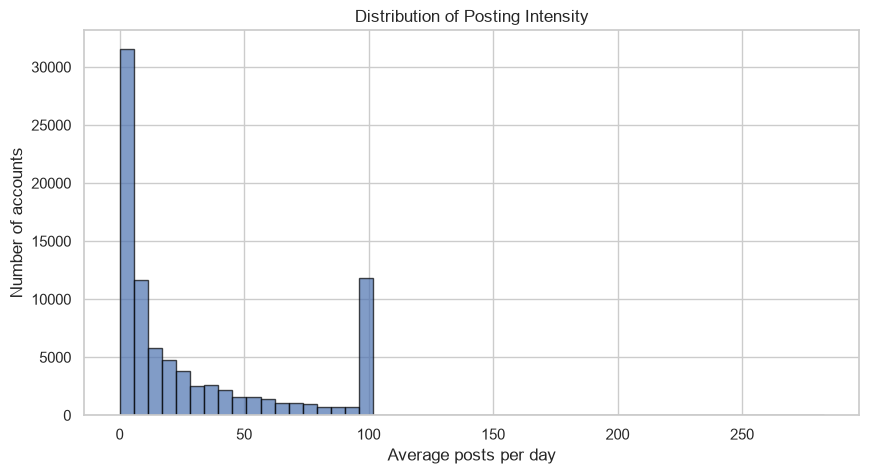

In [21]:
plt.figure(figsize=(10, 5))

plt.hist(
    df_activity["posting_intensity"].dropna(),
    bins=50,
    edgecolor="black",
    alpha=0.7
)

plt.title("Distribution of Posting Intensity")
plt.xlabel("Average posts per day")
plt.ylabel("Number of accounts")

plt.show()

#### Observations

The posting intensity distribution is right-skewed,
with a noticeable concentration at 99 posts per day.

Therefore, posting intensity may also be affected by
the previously identified potential sampling bias.

### B.5 Interaction Behavior

We analyze reposts, replies and mentions to characterize
how accounts interact with other users and disseminate
information.

we will use rations to make the comparison fair between accounts (we want to study the behavior)


In [22]:
columns = account_keys + [
    "is_repost",
    "in_reply_to_postid",
    "in_reply_to_accountid",
    "account_mentions"
]

interaction_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    # Identify reposts
    repost_status = chunk["is_repost"].str.strip().str.lower()

    chunk["repost"] = repost_status.eq("true").fillna(False)
    chunk["known_repost"] = repost_status.isin(["true", "false"])

    # Identify replies
    chunk["reply"] = (
        chunk["in_reply_to_postid"].notna() |
        chunk["in_reply_to_accountid"].notna()
    )

    # Identify posts containing mentions
    mentions = chunk["account_mentions"].str.strip()

    chunk["known_mentions"] = (
        mentions.str.startswith("[", na=False) &
        mentions.str.endswith("]", na=False)
    )

    chunk["has_mention"] = (
        chunk["known_mentions"] &
        ~mentions.str.fullmatch(r"\[\s*\]", na=False)
    )

    # Aggregate information per account
    stats = chunk.groupby(account_keys).agg(
        post_count=("accountid", "size"),
        repost_count=("repost", "sum"),
        known_repost_count=("known_repost", "sum"),
        reply_count=("reply", "sum"),
        mention_count=("has_mention", "sum"),
        known_mention_count=("known_mentions", "sum")
    )

    interaction_chunks.append(stats)

df_interactions = (
    pd.concat(interaction_chunks)
    .groupby(level=[0, 1])
    .sum()
    .reset_index()
)

In [23]:
df_interactions["repost_ratio"] = (
    df_interactions["repost_count"]
    / df_interactions["known_repost_count"].replace(0, np.nan)
)

df_interactions["reply_ratio"] = (
    df_interactions["reply_count"]
    / df_interactions["post_count"]
)

df_interactions["mention_ratio"] = (
    df_interactions["mention_count"]
    / df_interactions["known_mention_count"].replace(0, np.nan)
)

In [24]:
interaction_features = [
    "repost_ratio",
    "reply_ratio",
    "mention_ratio"
]

display(
    df_interactions[interaction_features]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
repost_ratio,86525.0,0.440623,0.398536,0.0,0.0,0.363636,0.877551,1.0,1.0,1.0
reply_ratio,86525.0,0.109589,0.191012,0.0,0.0,0.0,0.142857,0.538462,0.833333,1.0
mention_ratio,86525.0,0.613193,0.385763,0.0,0.25,0.737374,1.0,1.0,1.0,1.0


Each bin represents a ratio interval of 0.05 (5%).

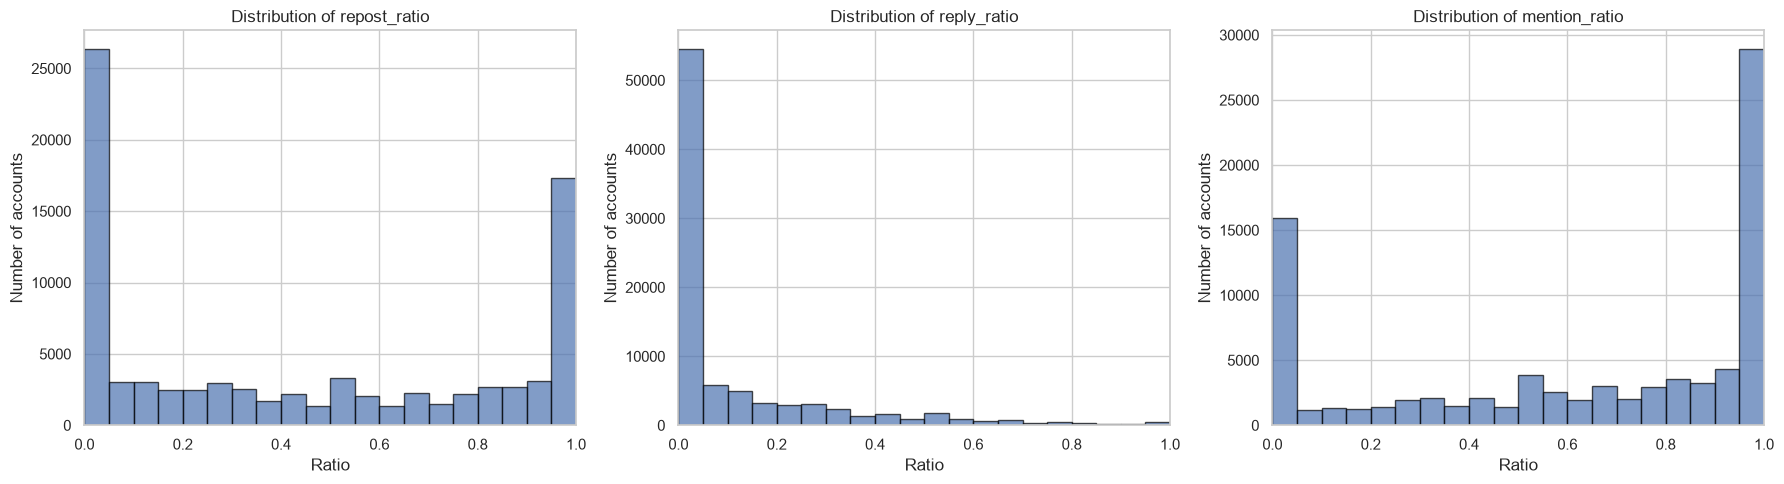

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, column in zip(axes, interaction_features):

    ax.hist(
        df_interactions[column].dropna(),
        bins=np.linspace(0, 1, 21),
        edgecolor="black",
        alpha=0.7
    )

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel("Ratio")
    ax.set_ylabel("Number of accounts")
    ax.set_xlim(0, 1)

plt.tight_layout()
plt.show()

reposts often contain mentions of the original author.
So potential redundancy between repost and mention ratios
will be investigated during correlation analysis.

Until now, we focused on how accounts behave. Next, we want to examine the characteristics of the content they publish.4
This can be useful for distinguishing behavioral patterns between IO and control accounts.

we will get things like do accounts use hashtags in posts, urls, etc, this can also help us in clustering

In [26]:
content_sample = pd.read_csv(
    DATA_PATH,
    usecols=["hashtags", "urls", "post_text"],
    dtype="string",
    nrows=10000
)

print("Hashtags:")
display(
    content_sample["hashtags"]
    .value_counts(dropna=False)
    .head(10)
)

print("URLs:")
display(
    content_sample["urls"]
    .value_counts(dropna=False)
    .head(10)
)

print("Post text examples:")
display(content_sample["post_text"].head(5))

Hashtags:


hashtags
[]                                                                                                                   7814
['LaCrudaVerdad']                                                                                                     202
['LCV']                                                                                                               124
['nowplaying']                                                                                                        111
['FF']                                                                                                                 73
['RT' 'FF' 'TeamFollowBack' '500ADAY' 'FollowAll' 'FollowFriday' 'Friday'\n 'autofollow' 'FollowBack' 'FollowMe']      35
['lacrudaverdad']                                                                                                      32
['FF' 'TeamFollowBack' 'FollowAll' 'autofollow' 'FollowBack' 'FollowMe']                                               32
['VzlaOffRoad']

URLs:


urls
[]                                                        9216
['https://20cf09697662227e7f7635f02e4c3663e52999e877']      61
['https://46926622555b6e7d8b3db9eceefc18560aee799169']      21
['https://64bd920098f09dd6b78acdae516e9f398d0b86ef19']      13
['https://01af12ee6e9b4b728ae4b6fe07fe80977095692160']       9
['https://e79bd02d6df9c731de356df4d03ef11a3ad60694ae']       6
['https://48d372bac2ae1efa2805f0b624bc83077e50e48796']       5
['https://d3865712d27f07cac336e5c489e3434d1bb08430ab']       4
['https://51453886766b1616f04cbc7a3ca084703dccc56c11']       4
['https://5929a59f2dc4a5bd3ae966cbce9a6f2ab0cb4c31a7']       3
Name: count, dtype: int64[pyarrow]

Post text examples:


0    Vamos a cambiar la forma de hacer comunicación...
1    Damos servicio de manejo de prensa, elaboració...
2    @db7c47cef2aa2ba68b5c010d761a03fc1c0f0d1302 Bu...
3    Mario, debemos denuciar que en los poderes pub...
4    Tambien debemos estar claro que la oposición e...
Name: post_text, dtype: string

In [27]:
columns = account_keys + ["hashtags", "urls", "post_text"]

content_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    # Hashtags
    hashtags = chunk["hashtags"].str.strip()

    chunk["known_hashtags"] = (
        hashtags.str.startswith("[", na=False) &
        hashtags.str.endswith("]", na=False)
    )

    chunk["has_hashtag"] = (
        chunk["known_hashtags"] &
        ~hashtags.str.fullmatch(r"\[\s*\]", na=False)
    )

    # URLs
    urls = chunk["urls"].str.strip()

    chunk["known_urls"] = (
        urls.str.startswith("[", na=False) &
        urls.str.endswith("]", na=False)
    )

    chunk["has_url"] = (
        chunk["known_urls"] &
        ~urls.str.fullmatch(r"\[\s*\]", na=False)
    )

    # Post length
    chunk["post_length"] = chunk["post_text"].str.len()
    chunk["known_text"] = chunk["post_text"].notna()

    # Aggregate per account
    stats = chunk.groupby(account_keys).agg(
        hashtag_posts=("has_hashtag", "sum"),
        known_hashtag_posts=("known_hashtags", "sum"),
        url_posts=("has_url", "sum"),
        known_url_posts=("known_urls", "sum"),
        total_post_length=("post_length", "sum"),
        known_text_posts=("known_text", "sum")
    )

    content_chunks.append(stats)

df_content = (
    pd.concat(content_chunks)
    .groupby(level=[0, 1])
    .sum()
    .reset_index()
)

# Calculate account-level features
df_content["hashtag_ratio"] = (
    df_content["hashtag_posts"]
    / df_content["known_hashtag_posts"].replace(0, np.nan)
)

df_content["url_ratio"] = (
    df_content["url_posts"]
    / df_content["known_url_posts"].replace(0, np.nan)
)

df_content["avg_post_length"] = (
    df_content["total_post_length"]
    / df_content["known_text_posts"].replace(0, np.nan)
)

In [28]:
content_features = [
    "hashtag_ratio",
    "url_ratio",
    "avg_post_length"
]

display(
    df_content[content_features]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
hashtag_ratio,86525.0,0.55549,0.321538,0.0,0.277778,0.5,0.890909,1.0,1.0,1.0
url_ratio,86525.0,0.551134,0.359306,0.0,0.222222,0.571429,0.928571,1.0,1.0,1.0
avg_post_length,86525.0,140.200512,65.717075,2.0,99.777778,132.333333,165.25,249.371011,332.5,2054.020202


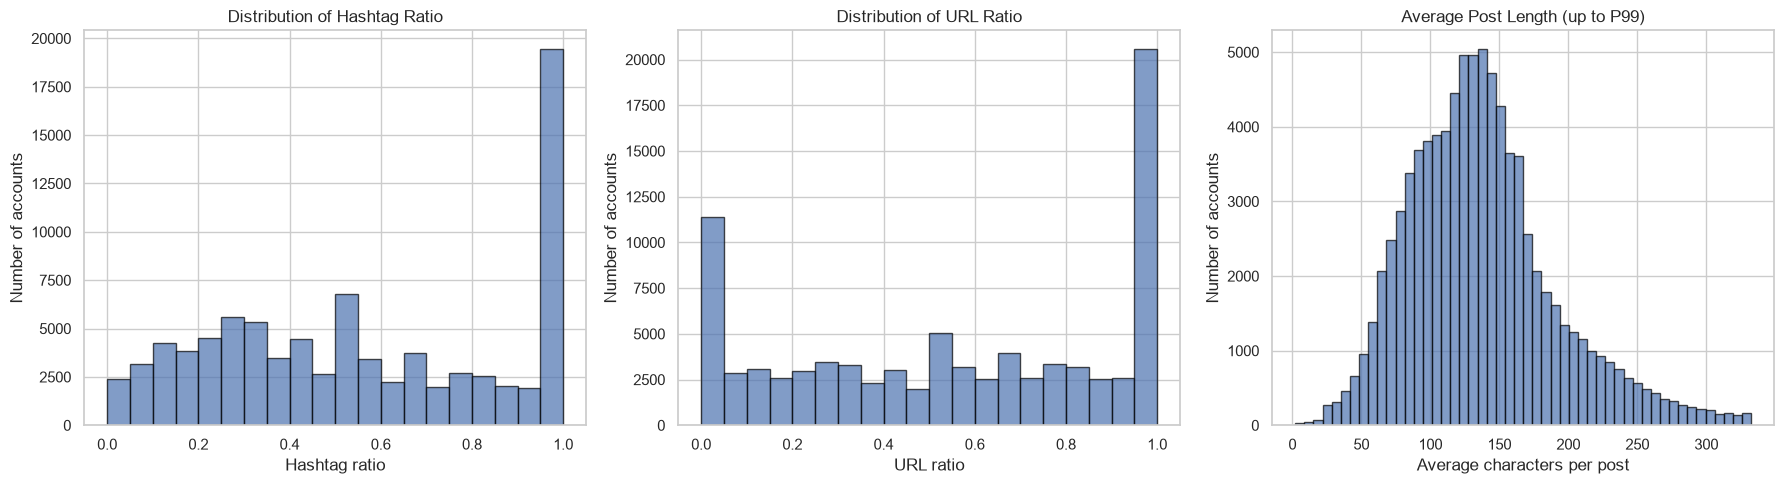

In [29]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Hashtag ratio
axes[0].hist(
    df_content["hashtag_ratio"].dropna(),
    bins=np.linspace(0, 1, 21),
    edgecolor="black",
    alpha=0.7
)
axes[0].set_title("Distribution of Hashtag Ratio")
axes[0].set_xlabel("Hashtag ratio")
axes[0].set_ylabel("Number of accounts")

# URL ratio
axes[1].hist(
    df_content["url_ratio"].dropna(),
    bins=np.linspace(0, 1, 21),
    edgecolor="black",
    alpha=0.7
)
axes[1].set_title("Distribution of URL Ratio")
axes[1].set_xlabel("URL ratio")
axes[1].set_ylabel("Number of accounts")

# Average post length
values = df_content["avg_post_length"].dropna()
upper_limit = values.quantile(0.99)

axes[2].hist(
    values[values <= upper_limit],
    bins=50,
    edgecolor="black",
    alpha=0.7
)
axes[2].set_title("Average Post Length (up to P99)")
axes[2].set_xlabel("Average characters per post")
axes[2].set_ylabel("Number of accounts")

plt.tight_layout()
plt.show()

### Language and Application Usage

We analyze the number of distinct languages and publishing
applications used by each account to investigate diversity
in communication and posting behavior.

In [30]:
columns = account_keys + ["post_language", "application_name"]

language_chunks = []
application_chunks = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=columns,
    dtype="string",
    chunksize=CHUNK_SIZE
):
    chunk = chunk.dropna(subset=account_keys)

    # Exclude missing or unspecified language labels
    languages = chunk.dropna(subset=["post_language"]).copy()
    languages["post_language"] = languages["post_language"].str.strip()
    languages = languages[
        ~languages["post_language"].str.lower().isin(["", "und", "unknown"])
    ]

    language_chunks.append(
        languages[account_keys + ["post_language"]].drop_duplicates()
    )

    # Identify distinct publishing applications
    applications = chunk.dropna(subset=["application_name"]).copy()
    applications["application_name"] = applications["application_name"].str.strip()
    applications = applications[applications["application_name"] != ""]

    application_chunks.append(
        applications[account_keys + ["application_name"]].drop_duplicates()
    )

# Remove duplicates across different chunks
unique_language_pairs = (
    pd.concat(language_chunks, ignore_index=True).drop_duplicates()
)

unique_application_pairs = (
    pd.concat(application_chunks, ignore_index=True).drop_duplicates()
)

# Count unique values for every account
language_counts = (
    unique_language_pairs.groupby(account_keys)
    .size()
    .rename("unique_languages")
    .reset_index()
)

application_counts = (
    unique_application_pairs.groupby(account_keys)
    .size()
    .rename("unique_applications")
    .reset_index()
)

df_diversity = (
    df_activity[account_keys].drop_duplicates()
    .merge(language_counts, on=account_keys, how="left")
    .merge(application_counts, on=account_keys, how="left")
)

df_diversity[["unique_languages", "unique_applications"]] = (
    df_diversity[["unique_languages", "unique_applications"]]
    .fillna(0)
    .astype(int)
)

In [31]:
diversity_features = [
    "unique_languages",
    "unique_applications"
]

display(
    df_diversity[diversity_features]
    .describe(percentiles=[0.25, 0.50, 0.75, 0.95, 0.99])
    .T
)

,count,mean,std,min,25%,50%,75%,95%,99%,max
unique_languages,86525.0,2.239503,2.359588,0.0,1.0,1.0,3.0,6.0,12.0,40.0
unique_applications,86525.0,1.652239,1.377811,1.0,1.0,1.0,2.0,4.0,7.0,69.0


In [32]:
for column in diversity_features:
    print(f"\n{column}")
    print(
        df_diversity[column]
        .value_counts()
        .sort_index()
        .head(15)
    )


unique_languages
unique_languages
0       887
1     44888
2     18603
3      8803
4      4706
5      2760
6      1898
7      1087
8       714
9       511
10      425
11      237
12      201
13      146
14      101
Name: count, dtype: int64

unique_applications
unique_applications
1     55297
2     19400
3      6937
4      2501
5       955
6       371
7       241
8       162
9        95
10      100
11      100
12      109
13       92
14       62
15       42
Name: count, dtype: int64


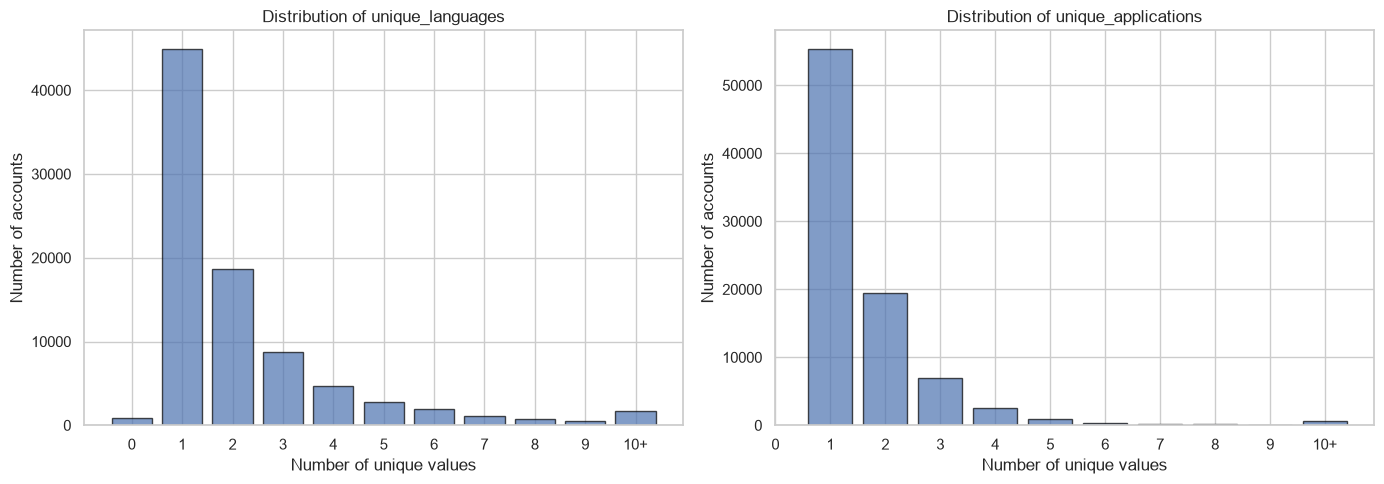

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, diversity_features):

    values = df_diversity[column]

    # Group larger values to simplify visualization
    grouped = values.clip(upper=10)
    counts = grouped.value_counts().sort_index()

    ax.bar(counts.index, counts.values, edgecolor="black", alpha=0.7)

    ax.set_title(f"Distribution of {column}")
    ax.set_xlabel("Number of unique values")
    ax.set_ylabel("Number of accounts")
    ax.set_xticks(range(11))
    ax.set_xticklabels([str(i) for i in range(10)] + ["10+"])

plt.tight_layout()
plt.show()

#### Observations

Most accounts use only one identified language (51.9%)
and one publishing application (63.9%).

A smaller proportion uses multiple languages or applications,
indicating different levels of diversity.

These features may be useful for clustering, also, their
relationship with posting volume should be considered(more posts -> more opportunities to use different languages).

## C. Correlation Analysis

We investigate relationships between numerical account-level
features to identify potential redundancy.

Spearman correlation is used because several features have
skewed distributions and extreme values.

During the previous analysis, we extracted original account attributes and created new behavioral features, such as posting intensity, interaction ratios, and content characteristics.

We now combine these features into a single account-level dataframe.

In [ ]:
# New account-level dataset for analysis
df_eda = df_activity[
    account_keys + ["post_count", "posting_intensity"]
].copy()

# Merge the features calculated in previous sections
feature_tables = [
    df_accounts[
        account_keys + ["follower_count", "following_count"]
    ],
    df_temporal[
        account_keys + ["account_age_days", "activity_lifespan_days"]
    ],
    df_interactions[
        account_keys + ["repost_ratio", "reply_ratio", "mention_ratio"]
    ],
    df_content[
        account_keys + ["hashtag_ratio", "url_ratio", "avg_post_length"]
    ],
    df_diversity[
        account_keys + ["unique_languages", "unique_applications"]
    ]
]

for table in feature_tables:
    df_eda = df_eda.merge(
        table,
        on=account_keys,
        how="left",
        validate="one_to_one"
    )

print("Number of account profiles:", len(df_eda))
print("Number of attributes:", len(df_eda.columns))

# Display all attributes
print("\nAttributes:")
for column in df_eda.columns:
    print("-", column)

# Display the first five account profiles
display(df_eda.head())

Number of account profiles: 86525
Number of attributes: 16

Attributes:
- ioCountry
- accountid
- post_count
- posting_intensity
- follower_count
- following_count
- account_age_days
- activity_lifespan_days
- repost_ratio
- reply_ratio
- mention_ratio
- hashtag_ratio
- url_ratio
- avg_post_length
- unique_languages
- unique_applications


,ioCountry,accountid,post_count,posting_intensity,follower_count,following_count,account_age_days,activity_lifespan_days,repost_ratio,reply_ratio,mention_ratio,hashtag_ratio,url_ratio,avg_post_length,unique_languages,unique_applications
0,ecuador,001ffbe241e63935ce176d64177e9d736a9cab1248,2,2.000000,266.0,330.0,2532,0,0.0,0.0,1.0,1.0,1.0,178.5,1,1
1,ecuador,0021f0f41422c32c9e3d7a96014bc6359c64d3214d,86,0.036768,795.0,973.0,3187,2338,0.430233,0.151163,0.883721,0.313953,0.186047,121.55814,2,2
2,ecuador,00280fff71800b03c0b67be0ffc573b25af74a0d50,2,2.000000,81.0,739.0,2456,0,0.5,0.0,1.0,1.0,0.5,143.0,1,1
3,ecuador,003f8ea49234bfc9a19716b3ea07aaf508501b748e,10,10.000000,256.0,1464.0,2362,0,1.0,0.0,1.0,1.0,1.0,490.9,1,1
4,ecuador,005283930b48906c08bde2afc691cdec149b471ddd,15,15.000000,723.0,600.0,739,0,0.0,0.0,0.133333,0.4,0.066667,72.133333,4,1


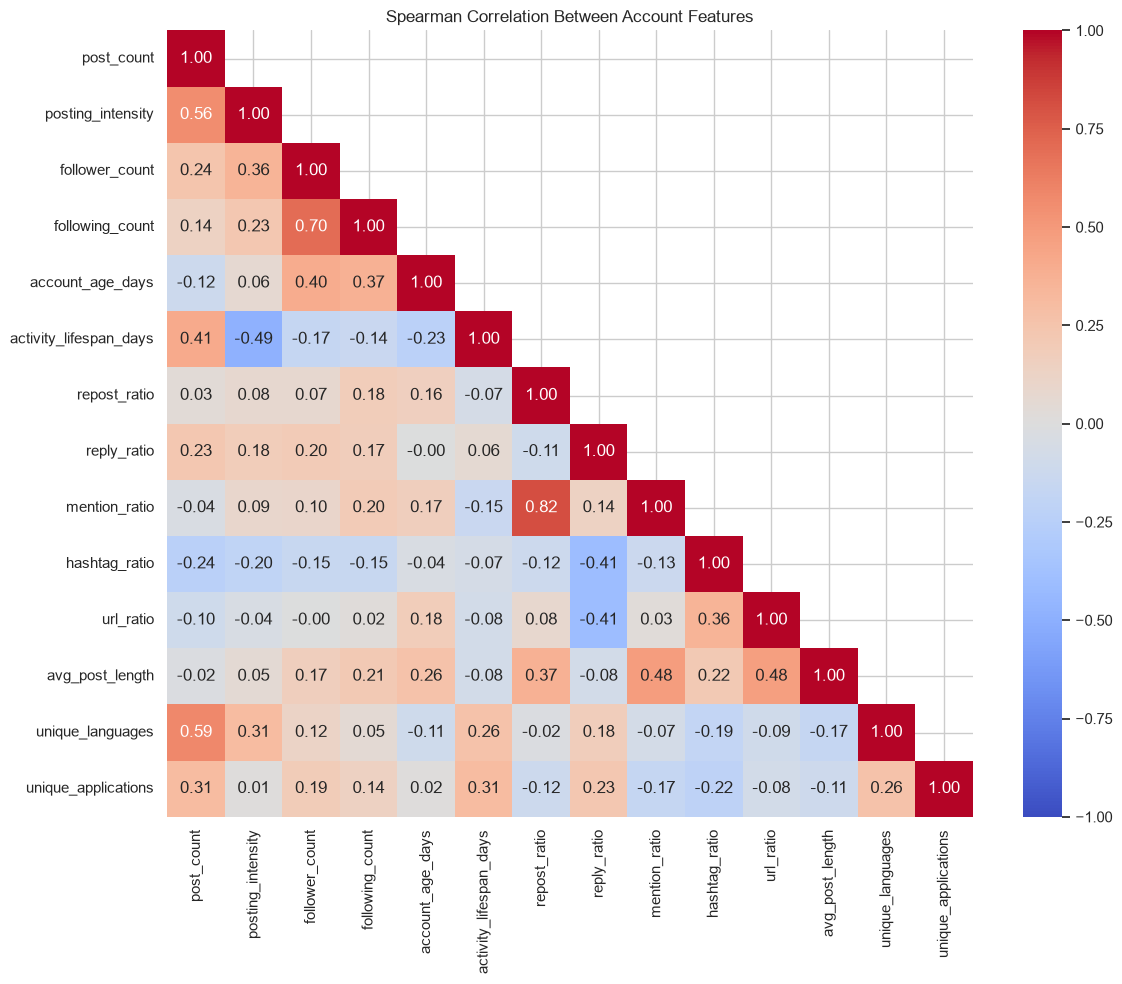

In [38]:
# Calculate Spearman correlation
correlation_matrix = df_eda.drop(columns=account_keys).corr(method="spearman")

# Hide the upper triangle (duplicate correlations)
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool), k=1)

plt.figure(figsize=(12, 10))

sns.heatmap(
    correlation_matrix,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Spearman Correlation Between Account Features")
plt.tight_layout()
plt.show()

#### Correlation Analysis — Observations

- A strong positive correlation (+0.82) exists between
  repost_ratio and mention_ratio, suggesting potential redundancy.
- Follower and following counts are positively correlated (+0.70).
- Post count and unique languages are moderately correlated (+0.59),
  possibly reflecting differences in observed posting volume.
- Posting intensity and activity lifespan are negatively correlated
  (-0.49), partly due to how posting intensity is calculated.
- Highly correlated features will be reconsidered during
  feature selection to avoid unnecessary redundancy in clustering.

Until now, we analyzed all accounts together. We will now compare Information Operations (IO) accounts with control accounts to understand how their behavior differs.

In [39]:
# Add the account labels to our account-level dataset
df_comparison = df_eda.merge(
    df_labels[account_keys + ["is_control"]],
    on=account_keys,
    how="left",
    validate="one_to_one"
)

# Create readable group names
df_comparison["account_group"] = (
    df_comparison["is_control"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({"false": "IO", "true": "Control"})
)

print("Total account profiles:", len(df_comparison))

print("\nAccounts by group:")
print(df_comparison["account_group"].fillna("Unknown").value_counts())

print("\nAccounts by operation and group:")
display(
    pd.crosstab(
        df_comparison["ioCountry"],
        df_comparison["account_group"].fillna("Unknown")
    )
)

Total account profiles: 86525

Accounts by group:
account_group
Control    75608
IO         10916
Unknown        1
Name: count, dtype: int64

Accounts by operation and group:


account_group,Control,IO,Unknown
ioCountry,,,
ecuador,21137,786,1
iran_1,5015,660,0
iran_4,7612,2519,0
russia_1,31299,3293,0
uae,10545,3658,0


In [40]:
# Main behavioral features to compare
behavior_features = [
    "post_count",
    "posting_intensity",
    "repost_ratio",
    "reply_ratio",
    "mention_ratio",
    "hashtag_ratio",
    "url_ratio",
    "avg_post_length"
]

# Exclude the one account with an unresolved label
df_valid = df_comparison[
    df_comparison["account_group"].isin(["IO", "Control"])
]

# Calculate median feature values for both groups
group_medians = (
    df_valid
    .groupby("account_group")[behavior_features]
    .median()
    .T
)

# Add the difference between IO and Control
group_medians["Difference (IO - Control)"] = (
    group_medians["IO"] - group_medians["Control"]
)

display(group_medians.round(3))

account_group,Control,IO,Difference (IO - Control)
post_count,20.0,88.0,68.0
posting_intensity,16.0,1.068496,-14.931504
repost_ratio,0.380952,0.306047,-0.074905
reply_ratio,0.0,0.023166,0.023166
mention_ratio,0.777778,0.508511,-0.269267
hashtag_ratio,0.518519,0.4,-0.118519
url_ratio,0.625,0.358737,-0.266263
avg_post_length,135.818182,118.689705,-17.128477


These results suggest that IO and control accounts exhibit different posting, interaction, and content behaviors. Such differences may help us identify useful features for clustering.

### D.3 — Distribution Comparison

We compare the distributions of selected features between IO and control accounts to better understand their differences and determine how much the groups overlap.

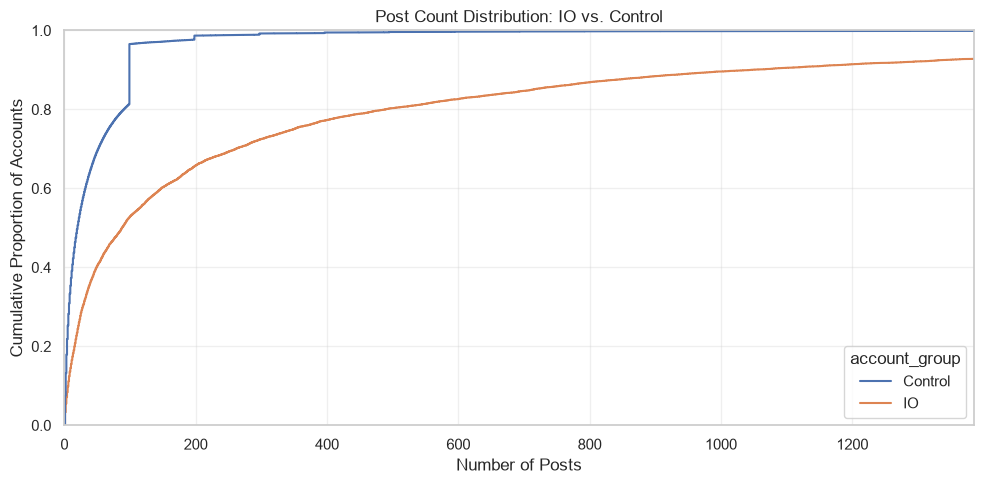

In [43]:
plt.figure(figsize=(10, 5))

sns.ecdfplot(
    data=df_valid,
    x="post_count",
    hue="account_group",
    hue_order=["Control", "IO"]
)

# Focus on the first 99% of observed post counts
plt.xlim(0, df_valid["post_count"].quantile(0.99))

plt.title("Post Count Distribution: IO vs. Control")
plt.xlabel("Number of Posts")
plt.ylabel("Cumulative Proportion of Accounts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

IO accounts generally have higher observed post counts than control accounts.

However, notice the sharp increase in the blue curve around 99 posts. This relates to the unusual concentration of control accounts with exactly 99 posts that we identified earlier.

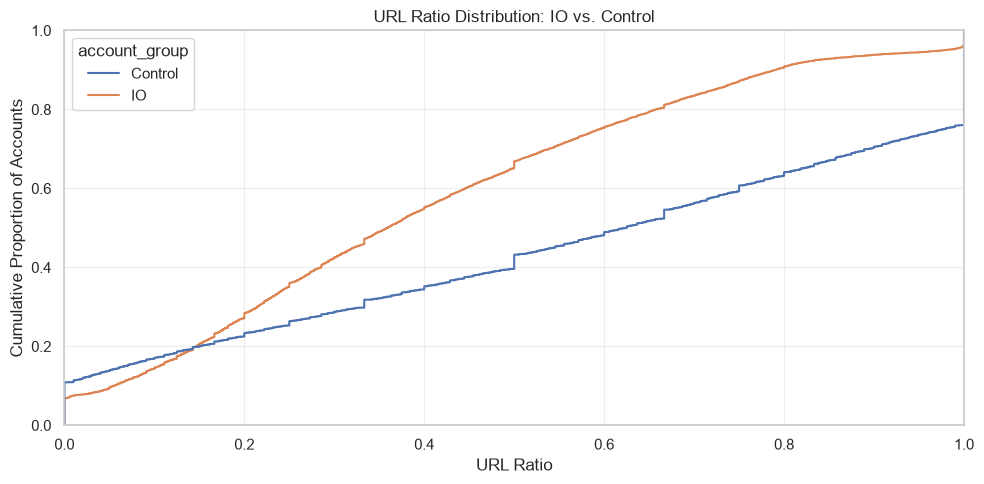

In [44]:
plt.figure(figsize=(10, 5))

sns.ecdfplot(
    data=df_valid,
    x="url_ratio",
    hue="account_group",
    hue_order=["Control", "IO"]
)

plt.xlim(0, 1)
plt.title("URL Ratio Distribution: IO vs. Control")
plt.xlabel("URL Ratio")
plt.ylabel("Cumulative Proportion of Accounts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### URL Ratio Distribution — Observations

- Control accounts generally have higher URL ratios than IO accounts.
- Both groups show overlapping distributions.
- URL ratio may be a useful feature for clustering, but it cannot distinguish the groups on its own.

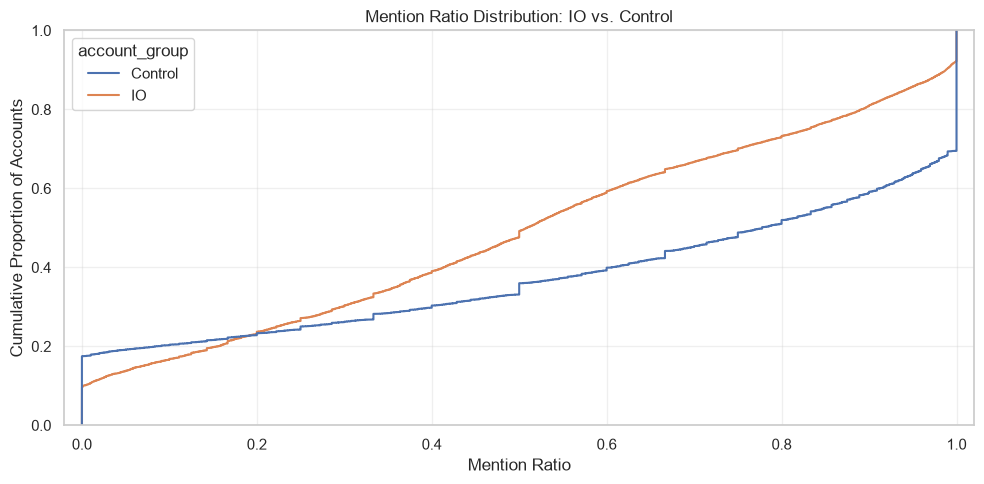

In [46]:
plt.figure(figsize=(10, 5))

sns.ecdfplot(
    data=df_valid,
    x="mention_ratio",
    hue="account_group",
    hue_order=["Control", "IO"]
)

plt.xlim(-0.02, 1.02)
plt.title("Mention Ratio Distribution: IO vs. Control")
plt.xlabel("Mention Ratio")
plt.ylabel("Cumulative Proportion of Accounts")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### Mention Ratio Distribution — Observations

- Control accounts generally have higher mention ratios than IO accounts.
- A substantial proportion of control accounts have a mention ratio of 1.
- Both groups have overlapping distributions, so mention ratio alone cannot reliably distinguish them.
- Mention and repost ratios are strongly correlated, suggesting potentially redundant information.

In [47]:
# Save account-level features for the next stage
ACCOUNT_FEATURES_PATH = DATA_PATH.parent / "df_account_features_eda.csv.gz"

df_eda.to_csv(
    ACCOUNT_FEATURES_PATH,
    index=False,
    compression="gzip"
)

print("Dataset saved to:", ACCOUNT_FEATURES_PATH)
print("Account profiles:", len(df_eda))
print("Numerical features:", len(df_eda.columns) - len(account_keys))

Dataset saved to: data_processed\df_account_features_eda.csv.gz
Account profiles: 86525
Numerical features: 14
